# Department-wise Retention Strategy
Employee Attrition Risk Analyzer

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE = "#1F3A5F"

risk = pd.read_csv("../data/processed/risk_with_reasons.csv")
clean = pd.read_csv("../data/processed/cleaned_data.csv")

extra = ["EmployeeNumber", "RiskScore", "RiskLevel", "Top_Reasons",
         "Action1", "Action2", "Action3", "Top_Actionable_Reasons"]
final = clean.merge(risk[extra], on="EmployeeNumber", how="left")
for c in ["Action1", "Action2", "Action3"]:
    final[c] = final[c].fillna("")

print(final.shape, "| missing risk scores:", final["RiskScore"].isna().sum())


(1470, 39) | missing risk scores: 0


In [2]:
LABEL = {
    "OverTime": "Overtime",
    "BusinessTravel_Travel_Frequently": "Frequent Business Travel",
    "EnvironmentSatisfaction": "Low Environment Satisfaction",
    "YearsSinceLastPromotion": "Long Time Since Promotion",
    "YearsWithCurrManager": "Long Time with Same Manager",
    "JobSatisfaction": "Low Job Satisfaction",
    "DistanceFromHome": "Long Commute Distance",
    "JobInvolvement": "Low Job Involvement",
    "MonthlyIncome": "Low Monthly Income",
    "StockOptionLevel": "Low Stock Option Level",
    "TrainingTimesLastYear": "Low Training Exposure",
    "YearsInCurrentRole": "Stagnation in Current Role",
    "PercentSalaryHike": "Low Salary Hike",
    "RelationshipSatisfaction": "Low Relationship Satisfaction",
    "WorkLifeBalance": "Poor Work-Life Balance",
}

REC = {
    "OverTime": "Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.",
    "BusinessTravel_Travel_Frequently": "Reduce travel through virtual meetings, rotate travel duties and provide travel allowances or compensatory leave.",
    "EnvironmentSatisfaction": "Run pulse surveys and improve workspace, tools and team facilities.",
    "YearsSinceLastPromotion": "Define clear career paths and review promotion eligibility for long-waiting employees.",
    "YearsWithCurrManager": "Provide manager training, regular one-to-one meetings and consider team rotation.",
    "JobSatisfaction": "Enrich roles, introduce recognition programs and collect regular feedback.",
    "DistanceFromHome": "Offer hybrid or remote work options and commute or relocation support.",
    "JobInvolvement": "Give project ownership and cross-functional assignments to increase engagement.",
    "MonthlyIncome": "Benchmark salaries against the market and add performance-linked incentives.",
    "StockOptionLevel": "Introduce or extend stock options and long-term incentives.",
    "TrainingTimesLastYear": "Provide more training and upskilling opportunities.",
    "YearsInCurrentRole": "Offer job rotation or lateral moves to reduce stagnation.",
    "PercentSalaryHike": "Review the increment policy for fairness and performance linkage.",
    "RelationshipSatisfaction": "Conduct team-building activities and mentoring programs.",
    "WorkLifeBalance": "Introduce flexible hours and wellness programs.",
}

In [3]:
shap_df = pd.read_csv("../data/processed/shap_values.csv")
Xm = pd.read_csv("../data/processed/model_ready_data.csv").drop(columns=["Attrition"])

direction = {}
for f in LABEL:
    if f in Xm.columns:
        c = np.corrcoef(Xm[f], shap_df[f])[0, 1]
        direction[f] = "HIGH" if c > 0 else "LOW"

print("Value that RAISES risk:")
print(pd.Series(direction).to_string())

if direction.get("YearsWithCurrManager") == "LOW":
    LABEL["YearsWithCurrManager"] = "Recent Manager Change"
    REC["YearsWithCurrManager"] = ("Support employees who recently got a new manager with onboarding, "
                                   "mentoring and regular one-to-one check-ins in the first year.")

if direction.get("YearsInCurrentRole") == "LOW":
    LABEL["YearsInCurrentRole"] = "Recently Moved into Role"
    REC["YearsInCurrentRole"] = ("Provide role onboarding, clear expectations and mentoring "
                                 "for employees who recently changed roles.")

Value that RAISES risk:
OverTime                            HIGH
BusinessTravel_Travel_Frequently    HIGH
EnvironmentSatisfaction              LOW
YearsSinceLastPromotion             HIGH
YearsWithCurrManager                 LOW
JobSatisfaction                      LOW
DistanceFromHome                    HIGH
JobInvolvement                       LOW
MonthlyIncome                        LOW
StockOptionLevel                     LOW
TrainingTimesLastYear                LOW
YearsInCurrentRole                   LOW
PercentSalaryHike                    LOW
RelationshipSatisfaction             LOW
WorkLifeBalance                      LOW


In [4]:
dept = final.groupby("Department").agg(
    Employees=("EmployeeNumber", "count"),
    Avg_Risk_Score=("RiskScore", "mean"),
    High_Risk=("RiskLevel", lambda s: (s == "High").sum()),
    Actual_Attrition_Pct=("Attrition", lambda s: (s == "Yes").mean() * 100),
).round(1)
dept["High_Risk_Pct"] = (dept["High_Risk"] / dept["Employees"] * 100).round(1)
dept.to_csv("../outputs/tables/department_risk_summary.csv")
dept

,Employees,Avg_Risk_Score,High_Risk,Actual_Attrition_Pct,High_Risk_Pct
Department,,,,,
Human Resources,63,40.2,20,19.0,31.7
Research & Development,961,32.4,197,13.8,20.5
Sales,446,42.2,141,20.6,31.6


In [5]:
at_risk = final[final["RiskLevel"].isin(["Medium", "High"])]

rows = []
for d, g in at_risk.groupby("Department"):
    n = len(g)
    counts = (pd.concat([g["Action1"], g["Action2"], g["Action3"]])
                .replace("", np.nan).dropna().value_counts())
    for rank, (f, c) in enumerate(counts.head(3).items(), start=1):
        rows.append({
            "Department": d,
            "Rank": rank,
            "Risk Factor": LABEL.get(f, f),
            "At-Risk Employees Affected (%)": round(c / n * 100, 1),
            "Recommended Strategy": REC.get(f, "Conduct stay interviews."),
        })

strategy = pd.DataFrame(rows)
strategy.to_csv("../data/final/department_strategy.csv", index=False)
pd.set_option("display.max_colwidth", 120)
strategy

,Department,Rank,Risk Factor,At-Risk Employees Affected (%),Recommended Strategy
0,Human Resources,1,Recent Manager Change,48.6,"Support employees who recently got a new manager with onboarding, mentoring and regular one-to-one check-ins in the ..."
1,Human Resources,2,Low Environment Satisfaction,45.7,"Run pulse surveys and improve workspace, tools and team facilities."
2,Human Resources,3,Overtime,34.3,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
3,Research & Development,1,Overtime,48.1,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
4,Research & Development,2,Recent Manager Change,42.9,"Support employees who recently got a new manager with onboarding, mentoring and regular one-to-one check-ins in the ..."
5,Research & Development,3,Low Environment Satisfaction,35.3,"Run pulse surveys and improve workspace, tools and team facilities."
6,Sales,1,Recent Manager Change,43.9,"Support employees who recently got a new manager with onboarding, mentoring and regular one-to-one check-ins in the ..."
7,Sales,2,Overtime,40.7,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
8,Sales,3,Low Environment Satisfaction,38.3,"Run pulse surveys and improve workspace, tools and team facilities."


In [6]:
role = final.groupby("JobRole").agg(
    Employees=("EmployeeNumber", "count"),
    High_Risk_Pct=("RiskLevel", lambda s: (s == "High").mean() * 100),
).round(1).sort_values("High_Risk_Pct", ascending=False)
role.to_csv("../outputs/tables/jobrole_risk_summary.csv")
role

,Employees,High_Risk_Pct
JobRole,,
Sales Representative,83,63.9
Human Resources,52,38.5
Laboratory Technician,259,37.1
Sales Executive,326,25.8
Research Scientist,292,22.9
Manufacturing Director,145,11.0
Healthcare Representative,131,8.4
Manager,102,7.8
Research Director,80,3.8


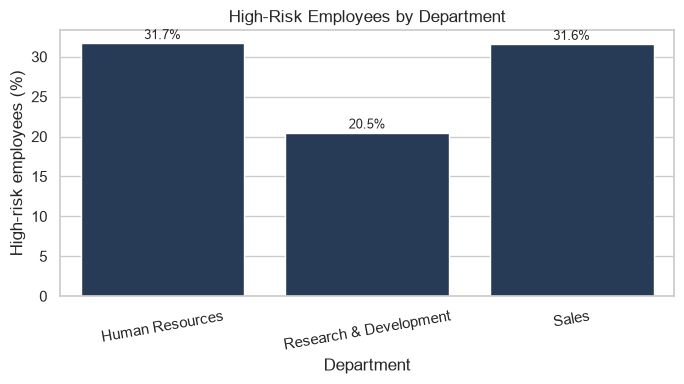

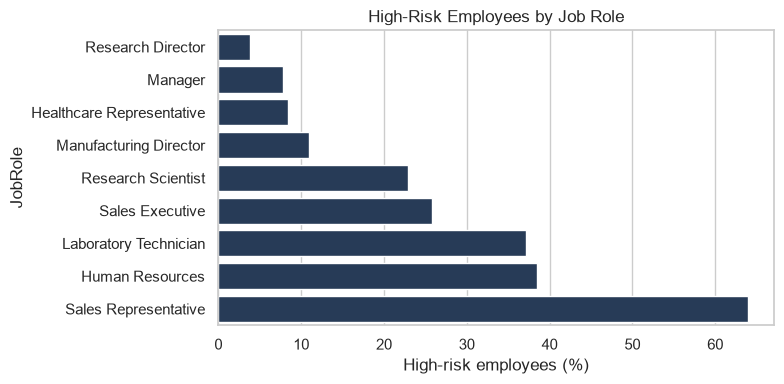

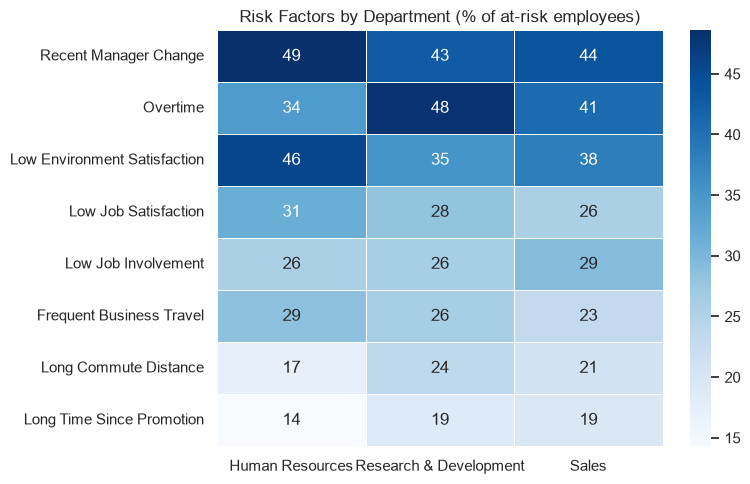

In [7]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=dept.index, y=dept["High_Risk_Pct"], color=BLUE)
for i, v in enumerate(dept["High_Risk_Pct"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
plt.ylabel("High-risk employees (%)")
plt.title("High-Risk Employees by Department")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("../outputs/charts/06_high_risk_by_department.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 4))
r = role["High_Risk_Pct"].sort_values()
sns.barplot(x=r.values, y=r.index, color=BLUE)
plt.xlabel("High-risk employees (%)")
plt.title("High-Risk Employees by Job Role")
plt.tight_layout()
plt.savefig("../outputs/charts/06_high_risk_by_jobrole.png", dpi=300)
plt.show()

# factor x department heatmap
mat = {}
for d, g in at_risk.groupby("Department"):
    c = (pd.concat([g["Action1"], g["Action2"], g["Action3"]])
           .replace("", np.nan).dropna().value_counts())
    mat[d] = (c / len(g) * 100)
heat = pd.DataFrame(mat).fillna(0)
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).head(8).index]
heat.index = [LABEL.get(i, i) for i in heat.index]

plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5)
plt.title("Risk Factors by Department (% of at-risk employees)")
plt.tight_layout()
plt.savefig("../outputs/charts/06_factor_department_heatmap.png", dpi=300)
plt.show()

In [8]:
final["Primary_Risk_Factor"] = final["Action1"].map(LABEL).fillna("")
final["Recommended_Action"] = np.where(
    final["RiskLevel"] == "Low",
    "Monitor - no action needed",
    final["Action1"].map(REC).fillna("Conduct a one-to-one stay interview."))
final.loc[final["RiskLevel"] == "Low", "Primary_Risk_Factor"] = ""

final.to_csv("../data/final/final_attrition_data.csv", index=False)

print(final.shape)
print(final["RiskLevel"].value_counts())
final[["EmployeeNumber", "Department", "RiskScore", "RiskLevel",
       "Primary_Risk_Factor", "Recommended_Action"]].head(8)

(1470, 41)
RiskLevel
Low       760
High      358
Medium    352
Name: count, dtype: int64


,EmployeeNumber,Department,RiskScore,RiskLevel,Primary_Risk_Factor,Recommended_Action
0,1,Sales,90.6,High,Overtime,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
1,2,Research & Development,10.7,Low,,Monitor - no action needed
2,4,Research & Development,85.1,High,Overtime,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
3,5,Research & Development,52.8,Medium,Frequent Business Travel,"Reduce travel through virtual meetings, rotate travel duties and provide travel allowances or compensatory leave."
4,7,Research & Development,60.1,High,Low Environment Satisfaction,"Run pulse surveys and improve workspace, tools and team facilities."
5,8,Research & Development,28.4,Low,,Monitor - no action needed
6,10,Research & Development,55.9,Medium,Overtime,Reduce mandatory overtime by redistributing workload and review overtime compensation or time-off policy.
7,11,Research & Development,20.4,Low,,Monitor - no action needed
